In [1]:
import numpy as np
import pandas as pd

## Encoding Categorical Data

### Ordinal Encoding

In [2]:
df = pd.read_csv('DataSets/customer.csv')

In [3]:
df.sample(5)

,age,gender,review,education,purchased
35,74,Male,Poor,School,Yes
49,25,Female,Good,UG,No
32,92,Male,Average,UG,Yes
2,70,Female,Good,PG,No
5,31,Female,Average,School,Yes


In [4]:
df = df.iloc[:,2:]    #Left gender cause it is nominal

In [5]:
df.head()

,review,education,purchased
0,Average,School,No
1,Poor,UG,No
2,Good,PG,No
3,Good,PG,No
4,Average,UG,No


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split (df.drop('purchased', axis=1), df['purchased'], test_size = 0.2, random_state = 0)

X_train.shape,  X_test.shape

((40, 2), (10, 2))

In [7]:
X_train.head(3)

,review,education
33,Good,PG
35,Poor,School
26,Poor,PG


In [8]:
X_test.head(3)

,review,education
28,Poor,School
11,Good,UG
10,Good,UG


In [9]:
print(X_train.columns)

Index(['review', 'education'], dtype='str')


In [10]:
from sklearn.preprocessing import OrdinalEncoder

oe = OrdinalEncoder(categories=[
    ['Poor','Average','Good'],
    ['School','UG','PG']    
])
#this categories is list of list type where number of list are equal to our ordinal features where Poor/Average/Good list is for review with Poor being given lowest value and Good being given highest value and same for education in next list

# (IMPORTANT) [if categories was not given then the values given to poor/average/good would be in sorted/alphabetical order automatically


oe.fit(X_train)

X_train = oe.transform(X_train)
X_test = oe.transform(X_test)

In [11]:
X_train

array([[2., 2.],
       [0., 0.],
       [0., 2.],
       [1., 0.],
       [2., 0.],
       [0., 0.],
       [0., 2.],
       [0., 2.],
       [2., 1.],
       [1., 1.],
       [0., 1.],
       [1., 1.],
       [1., 1.],
       [0., 1.],
       [2., 2.],
       [1., 0.],
       [0., 2.],
       [1., 1.],
       [1., 0.],
       [2., 0.],
       [1., 0.],
       [0., 1.],
       [2., 0.],
       [2., 1.],
       [0., 1.],
       [0., 0.],
       [1., 2.],
       [1., 2.],
       [2., 0.],
       [2., 0.],
       [2., 1.],
       [1., 2.],
       [0., 2.],
       [2., 1.],
       [0., 2.],
       [0., 2.],
       [2., 2.],
       [1., 0.],
       [2., 2.],
       [1., 1.]])

In [12]:
oe.categories_    #just a attribute

[array(['Poor', 'Average', 'Good'], dtype=object),
 array(['School', 'UG', 'PG'], dtype=object)]

### Label Encoding

In [13]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
#In this we do not have categories attribute so we cannot decide order it is sorted/alphabetically decided

le.fit(y_train)

y_train = le.transform(y_train)
y_test = le.transform(y_test)

In [14]:
le.classes_

array(['No', 'Yes'], dtype=object)

In [15]:
y_train

array([1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0])

### One Hot Encoding


In [16]:
df = pd.read_csv('DataSets/cars.csv')

In [17]:
df.head(3)

,brand,km_driven,fuel,owner,selling_price
0,Maruti,145500,Diesel,First Owner,450000
1,Skoda,120000,Diesel,Second Owner,370000
2,Honda,140000,Petrol,Third Owner,158000


In [18]:
df['brand'].value_counts()    # you will see some brands are selling a lot while some are seeling very few and there are many brands 

brand
Maruti           2448
Hyundai          1415
Mahindra          772
Tata              734
Toyota            488
Honda             467
Ford              397
Chevrolet         230
Renault           228
Volkswagen        186
BMW               120
Skoda             105
Nissan             81
Jaguar             71
Volvo              67
Datsun             65
Mercedes-Benz      54
Fiat               47
Audi               40
Lexus              34
Jeep               31
Mitsubishi         14
Land                6
Force               6
Isuzu               5
Kia                 4
Ambassador          4
MG                  3
Daewoo              3
Ashok               1
Opel                1
Peugeot             1
Name: count, dtype: int64

In [19]:
df['brand'].nunique()

32

In [20]:
df['fuel'].nunique()

4

#### 1. OneHotEncoding using Pandas

In [21]:
pd.get_dummies(df,columns=['fuel','owner']).head()

,brand,km_driven,selling_price,fuel_CNG,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,Maruti,145500,450000,False,True,False,False,True,False,False,False,False
1,Skoda,120000,370000,False,True,False,False,False,False,True,False,False
2,Honda,140000,158000,False,False,False,True,False,False,False,False,True
3,Hyundai,127000,225000,False,True,False,False,True,False,False,False,False
4,Maruti,120000,130000,False,False,False,True,True,False,False,False,False


#### 2. K-1 OneHotEncoding
This is the n-1 encoding

The problem with pandas is that it doesnt remember the column order or the column it has dropped

The changes done are not permanent changes

In [22]:
pd.get_dummies(df,columns=['fuel','owner'],drop_first=True)

,brand,km_driven,selling_price,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,Maruti,145500,450000,True,False,False,False,False,False,False
1,Skoda,120000,370000,True,False,False,False,True,False,False
2,Honda,140000,158000,False,False,True,False,False,False,True
3,Hyundai,127000,225000,True,False,False,False,False,False,False
4,Maruti,120000,130000,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
8123,Hyundai,110000,320000,False,False,True,False,False,False,False
8124,Hyundai,119000,135000,True,False,False,True,False,False,False
8125,Maruti,120000,382000,True,False,False,False,False,False,False
8126,Tata,25000,290000,True,False,False,False,False,False,False


#### 3. OneHotEncoding using Sklearn

In [23]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.iloc[:,0:4],df.iloc[:,-1],test_size=0.2,random_state=2)

In [24]:
X_train.head()

,brand,km_driven,fuel,owner
5571,Hyundai,35000,Diesel,First Owner
2038,Jeep,60000,Diesel,First Owner
2957,Hyundai,25000,Petrol,First Owner
7618,Mahindra,130000,Diesel,Second Owner
6684,Hyundai,155000,Diesel,First Owner


In [25]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder()
#ohe = OneHotEncoder(drop='first',sparse_output=False,dtype=np.int32)
# drop first is used to drop n encoding to n-1 by dropping first column
# sparse = False makes it such that we do not get a sparse matrix and there is no need to convert it to array

#the problem in this is that we first have to separate fuel and owner, apply one hot encoding and then merge with brand and km_driven as well

X_train_new = ohe.fit_transform(X_train[['fuel','owner']]).toarray()    #this does both in one line fit and transform
X_test_new = ohe.transform(X_test[['fuel','owner']]).toarray()

In [26]:
X_train_new    #9 columns cause we have 4 categories from fuel type and 5 from owner

array([[0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 1., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(6502, 9))

In [27]:
X_train[['brand','km_driven']]   #I got the first two columns but problem is that my encoded data is in numpy array and this is in dataframe

,brand,km_driven
5571,Hyundai,35000
2038,Jeep,60000
2957,Hyundai,25000
7618,Mahindra,130000
6684,Hyundai,155000
...,...,...
3606,Ford,35000
5704,Maruti,120000
6637,Tata,15000
2575,Maruti,32500


In [28]:
(X_train[['brand','km_driven']].values,X_train_new)    #So we do this to convert it to numpy array

(array([['Hyundai', 35000],
        ['Jeep', 60000],
        ['Hyundai', 25000],
        ...,
        ['Tata', 15000],
        ['Maruti', 32500],
        ['Isuzu', 121000]], shape=(6502, 2), dtype=object),
 array([[0., 1., 0., ..., 0., 0., 0.],
        [0., 1., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 1., 0., ..., 1., 0., 0.],
        [0., 1., 0., ..., 0., 0., 0.]], shape=(6502, 9)))

In [29]:
#This merges both
np.hstack((X_train[['brand','km_driven']].values,X_train_new))

array([['Hyundai', 35000, 0.0, ..., 0.0, 0.0, 0.0],
       ['Jeep', 60000, 0.0, ..., 0.0, 0.0, 0.0],
       ['Hyundai', 25000, 0.0, ..., 0.0, 0.0, 0.0],
       ...,
       ['Tata', 15000, 0.0, ..., 0.0, 0.0, 0.0],
       ['Maruti', 32500, 0.0, ..., 1.0, 0.0, 0.0],
       ['Isuzu', 121000, 0.0, ..., 0.0, 0.0, 0.0]],
      shape=(6502, 11), dtype=object)

#### 4. OneHotEncoding with Top Categories

In [30]:
counts = df['brand'].value_counts()
counts

brand
Maruti           2448
Hyundai          1415
Mahindra          772
Tata              734
Toyota            488
Honda             467
Ford              397
Chevrolet         230
Renault           228
Volkswagen        186
BMW               120
Skoda             105
Nissan             81
Jaguar             71
Volvo              67
Datsun             65
Mercedes-Benz      54
Fiat               47
Audi               40
Lexus              34
Jeep               31
Mitsubishi         14
Land                6
Force               6
Isuzu               5
Kia                 4
Ambassador          4
MG                  3
Daewoo              3
Ashok               1
Opel                1
Peugeot             1
Name: count, dtype: int64

In [31]:
#finding brands with value less than 100
repl = counts[counts <= 100].index
repl

Index(['Nissan', 'Jaguar', 'Volvo', 'Datsun', 'Mercedes-Benz', 'Fiat', 'Audi',
       'Lexus', 'Jeep', 'Mitsubishi', 'Land', 'Force', 'Isuzu', 'Kia',
       'Ambassador', 'MG', 'Daewoo', 'Ashok', 'Opel', 'Peugeot'],
      dtype='str', name='brand')

In [32]:
#Now brand names in repl are being replaced with Others and then doing the encoding
pd.get_dummies(df['brand'].replace(repl, 'Others')).sample(5)

,BMW,Chevrolet,Ford,Honda,Hyundai,Mahindra,Maruti,Others,Renault,Skoda,Tata,Toyota,Volkswagen
3979,False,False,False,False,True,False,False,False,False,False,False,False,False
2732,False,False,False,False,True,False,False,False,False,False,False,False,False
4943,False,False,False,False,False,True,False,False,False,False,False,False,False
3672,False,False,False,False,False,False,True,False,False,False,False,False,False
470,False,False,False,False,False,False,False,False,False,False,False,True,False


### Column Transformer
Different columns contains different data (numerical, ordinal categorical, nominal categorical etc) so we always have to separate them, apply different encoding methods and then merge them which is lot of trouble.
So we use Column Transformer 

In [33]:
df = pd.read_csv('DataSets/covid_toy.csv')
df.head()

,age,gender,fever,cough,city,has_covid
0,60,Male,103.0,Mild,Kolkata,No
1,27,Male,100.0,Mild,Delhi,Yes
2,42,Male,101.0,Mild,Delhi,No
3,31,Female,98.0,Mild,Kolkata,No
4,65,Female,101.0,Mild,Mumbai,No


In [34]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop(columns=['has_covid']), df['has_covid'], test_size=0.2)

X_train.head()

,age,gender,fever,cough,city
1,27,Male,100.0,Mild,Delhi
44,20,Male,102.0,Strong,Delhi
0,60,Male,103.0,Mild,Kolkata
98,5,Female,98.0,Strong,Mumbai
59,6,Female,104.0,Mild,Kolkata


In [35]:
X_test.head()

,age,gender,fever,cough,city
96,51,Female,101.0,Strong,Kolkata
14,51,Male,104.0,Mild,Bangalore
47,18,Female,104.0,Mild,Bangalore
91,38,Male,NaN,Mild,Delhi
31,83,Male,103.0,Mild,Kolkata


In [36]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

#### M1 -> Separating, Applying, Merging

In [37]:
# adding simple imputer to fever col
si = SimpleImputer()
X_train_fever = si.fit_transform(X_train[['fever']])

# also the test data
X_test_fever = si.fit_transform(X_test[['fever']])
                                 
X_train_fever.shape,  X_test_fever.shape

((80, 1), (20, 1))

In [38]:
# Ordinalencoding -> cough
oe = OrdinalEncoder(categories=[['Mild','Strong']])
X_train_cough = oe.fit_transform(X_train[['cough']])

# also the test data
X_test_cough = oe.fit_transform(X_test[['cough']])

X_train_cough.shape, X_test_cough.shape

((80, 1), (20, 1))

In [39]:
# OneHotEncoding -> gender,city
ohe = OneHotEncoder(drop='first',sparse_output=False)
X_train_gender_city = ohe.fit_transform(X_train[['gender','city']])

# also the test data
X_test_gender_city = ohe.fit_transform(X_test[['gender','city']])

X_train_gender_city.shape, X_test_gender_city.shape

((80, 4), (20, 4))

In [40]:
# Extracting Age
X_train_age = X_train.drop(columns=['gender','fever','cough','city']).values

# also the test data
X_test_age = X_test.drop(columns=['gender','fever','cough','city']).values

X_train_age.shape

(80, 1)

In [41]:
X_train_transformed = np.concatenate((X_train_age,X_train_fever,X_train_gender_city,X_train_cough),axis=1)
# also the test data
X_test_transformed = np.concatenate((X_test_age,X_test_fever,X_test_gender_city,X_test_cough),axis=1)

X_train_transformed.shape

(80, 7)

#### M2 -> Column Transformer

In [42]:
from sklearn.compose import ColumnTransformer

In [43]:
transformer = ColumnTransformer(transformers=[
    ('tnf1',SimpleImputer(),['fever']),
    ('tnf2',OrdinalEncoder(categories=[['Mild','Strong']]),['cough']),
    ('tnf3',OneHotEncoder(sparse_output=False,drop='first'),['gender','city'])
]
                                ,remainder='passthrough')

# In column transformers we have an attribute called transformers which is a list of tuples
#in each tupple we first send answers name tnf 1 2 3, telling which encoder to use, on which column to use. all separated by a comma

# We have second attribute named remainder which asks us what to do which remaining columns. drop means drop them and passthrough means leave them 

In [44]:
X_train_transformed = transformer.fit_transform(X_train)

In [45]:
X_test_transformed = transformer.transform(X_test)

In [46]:
transformer_df = pd.DataFrame(X_train_transformed)
transformer_df

,0,1,2,3,4,5,6
0,100.0,0.0,1.0,1.0,0.0,0.0,27.0
1,102.0,1.0,1.0,1.0,0.0,0.0,20.0
2,103.0,0.0,1.0,0.0,1.0,0.0,60.0
3,98.0,1.0,0.0,0.0,0.0,1.0,5.0
4,104.0,0.0,0.0,0.0,1.0,0.0,6.0
...,...,...,...,...,...,...,...
75,100.0,0.0,1.0,0.0,0.0,0.0,11.0
76,102.0,1.0,0.0,0.0,0.0,0.0,24.0
77,98.0,1.0,0.0,1.0,0.0,0.0,40.0
78,101.0,0.0,0.0,1.0,0.0,0.0,49.0


### Pipelines (Important)

#### Titanic Without pipelines

In [47]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier

In [48]:
df = pd.read_csv('DataSets/titanic.csv')
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [49]:
df.drop(columns=['PassengerId','Name','Ticket','Cabin'],inplace=True)    #removes useless columns

In [50]:
# Step 1 -> train/test/split
X_train,X_test,y_train,y_test = train_test_split(df.drop(columns=['Survived']), df['Survived'], test_size=0.2, random_state=42)

In [51]:
df.isnull().sum()   #we know that there are missing values

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [52]:
# Applying imputation ie fill missing values and then fit-transform

si_age = SimpleImputer()    #age missing values replaced with mean
si_embarked = SimpleImputer(strategy='most_frequent')    #embarked missing values replaced with most frequent boarding station

X_train_age = si_age.fit_transform(X_train[['Age']])
X_train_embarked = si_embarked.fit_transform(X_train[['Embarked']])

X_test_age = si_age.transform(X_test[['Age']])
X_test_embarked = si_embarked.transform(X_test[['Embarked']])



# One Hot Encoding Sex and Embarked and then fit-transform
#saath me kyu nahi kiya kyunki missing values hai jo fixed ki thi woh new numpy array me hai isliye column transformer not possible aur agar koi unknown value aaye toh use ignore kar dena yaani uski saari values zero
ohe_sex = OneHotEncoder(sparse_output=False,handle_unknown='ignore')
ohe_embarked = OneHotEncoder(sparse_output=False,handle_unknown='ignore')

X_train_sex = ohe_sex.fit_transform(X_train[['Sex']])
X_train_embarked = ohe_embarked.fit_transform(X_train_embarked)

X_test_sex = ohe_sex.transform(X_test[['Sex']])
X_test_embarked = ohe_embarked.transform(X_test_embarked)


#Separate the columns on which no operation was done(To merge with encoded columns)
X_train_rem = X_train.drop(columns=['Sex','Age','Embarked'])
X_test_rem = X_test.drop(columns=['Sex','Age','Embarked'])


#Merging all columns
X_train_transformed = np.concatenate((X_train_rem,X_train_age,X_train_sex,X_train_embarked),axis=1)
X_test_transformed = np.concatenate((X_test_rem,X_test_age,X_test_sex,X_test_embarked),axis=1)


#Now dataset is ready to be given to algorithm for training and testing
clf = DecisionTreeClassifier()
clf.fit(X_train_transformed,y_train)

y_pred = clf.predict(X_test_transformed)

In [53]:
# Now we check the accuracy of our model

from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.776536312849162

- So now we need to deploy model which will take input and predict and 
- To export data we use pickle
- we send our prediction model and one hot encoder model and simple imputer model cause user will give values and not numbers but our model is trained only on numbers and their may be cases of missing values

- without pipeline we will first give input and then has to run all the models ourselves and concatenate to make the data usable for model

#### Titanic With pipelines

In [54]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.feature_selection import SelectKBest,chi2
from sklearn.tree import DecisionTreeClassifier

In [55]:
df = pd.read_csv('DataSets/titanic.csv')
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


Now our pipeline will be 
1) Fill missing values
2) Apply one hot encoding
3) Do scaling
4) Feature Selection
5) Applying Algorithm

In [56]:
df.drop(columns=['PassengerId','Name','Ticket','Cabin'],inplace=True)    #removes useless columns

In [57]:
# Step 1 -> train/test/split
X_train,X_test,y_train,y_test = train_test_split(df.drop(columns=['Survived']), df['Survived'], test_size=0.2, random_state=42)


# Step 2 -> imputation transformer which fills missing values
trf1 = ColumnTransformer([
    ('impute_age',SimpleImputer(),[2]),
    ('impute_embarked',SimpleImputer(strategy='most_frequent'),[6])
],remainder='passthrough')
#NOTE IMP -> Now if you see column name is not given instead index is given cause we get numpy array in these and they only have index numbers not names so our pipeline may be destroyed if we give names 


# Step 3 -> one hot encoding
trf2 = ColumnTransformer([ ('ohe_sex_embarked',OneHotEncoder(sparse_output=False,handle_unknown='ignore'),[1,6])
],remainder='passthrough')


# Step 4 -> Scaling
trf3 = ColumnTransformer([
    ('scale',MinMaxScaler(),slice(0,10))
])

# Step 5 -> Feature selection
trf4 = SelectKBest(score_func=chi2,k=8)

# Step 6 -> train the model
trf5 = DecisionTreeClassifier()

In [58]:
#Creation of pipeline
pipe = Pipeline([
    ('trf1',trf1),
    ('trf2',trf2),
    ('trf3',trf3),
    ('trf4',trf4),
    ('trf5',trf5)
])

# Alternate Syntax
#pipe = make_pipeline(trf1,trf2,trf3,trf4,trf5)

# train
pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('trf1', ...), ('trf2', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('impute_age', ...), ('impute_embarked', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remain

In [59]:
# Explore the Pipeline ->   pipe.named_steps

# Display Pipeline like above flowchat
# from sklearn import set_config
# set_config(display='diagram')

In [60]:
# Predict
y_pred = pipe.predict(X_test)
accuracy_score(y_test,y_pred)

0.6256983240223464

### Cross Validation using Pipeline

In [61]:
# cross validation using cross_val_score
from sklearn.model_selection import cross_val_score
cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy').mean()

np.float64(0.6391214419383433)

### GridSearch using Pipeline

In [62]:
# gridsearchcv
params = {'trf5__max_depth':[1,2,3,4,5,None]}
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(pipe, params, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'trf5__max_depth': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitti

In [63]:
grid.best_score_

np.float64(0.6391214419383433)

In [64]:
grid.best_params_

{'trf5__max_depth': 2}

## Mathematical Transformation

In [65]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

### Log Transform

In [66]:
df = pd.read_csv('DataSets/titanic.csv',usecols=['Age','Fare','Survived'])
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [67]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [68]:
df['Age'] = df['Age'].fillna(df['Age'].mean())

In [69]:
X = df.iloc[:,1:3]
y = df.iloc[:,0]


X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train,y_train)
clf2.fit(X_train,y_train)
    
y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)
    
print("Accuracy LR without Log transform",accuracy_score(y_test,y_pred))
print("Accuracy DT without Log transform",accuracy_score(y_test,y_pred1))



#this func is used  to give custom function for transsformation.
#np.log would not run for 0 but np.log1p will add 1 to value and then log so 0 is never encountered
trf = FunctionTransformer(func=np.log1p)

X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed,y_train)
    
y_pred = clf.predict(X_test_transformed)
y_pred1 = clf2.predict(X_test_transformed)
    
print("Accuracy LR with Log transform",accuracy_score(y_test,y_pred))
print("Accuracy DT with Log transform",accuracy_score(y_test,y_pred1))


#Not taught yet but this is cross validation
X_transformed = trf.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR after Cross Validation",np.mean(cross_val_score(clf,X_transformed,y,scoring='accuracy',cv=10)))
print("DT after Cross Validation",np.mean(cross_val_score(clf2,X_transformed,y,scoring='accuracy',cv=10)))

Accuracy LR without Log transform 0.6480446927374302
Accuracy DT without Log transform 0.664804469273743
Accuracy LR with Log transform 0.6815642458100558
Accuracy DT with Log transform 0.6871508379888268
LR after Cross Validation 0.678027465667915
DT after Cross Validation 0.655505617977528


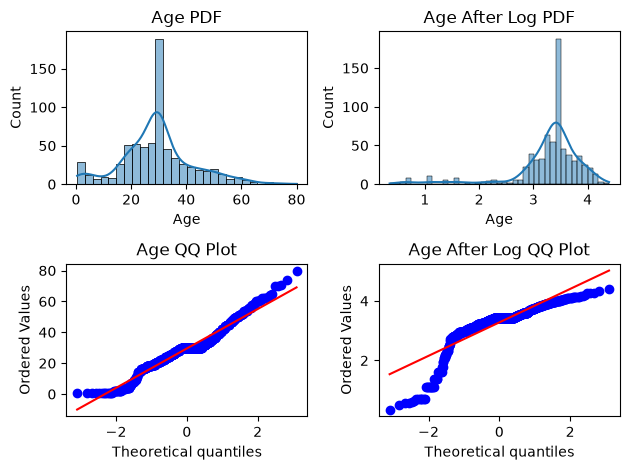

In [70]:
# Before log histogram + KDE
plt.subplot(2,2,1)
sns.histplot(X_train['Age'], kde=True)
plt.title('Age PDF')

# After log histogram + KDE
plt.subplot(2,2,2)
sns.histplot(X_train_transformed['Age'], kde=True)
plt.title('Age After Log PDF')

# Before log QQ plot
plt.subplot(2,2,3)
stats.probplot(X_train['Age'], dist="norm", plot=plt)
plt.title('Age QQ Plot')

# After log QQ plot
plt.subplot(2,2,4)
stats.probplot(X_train_transformed['Age'], dist="norm", plot=plt)
plt.title('Age After Log QQ Plot')

plt.tight_layout()
plt.show()

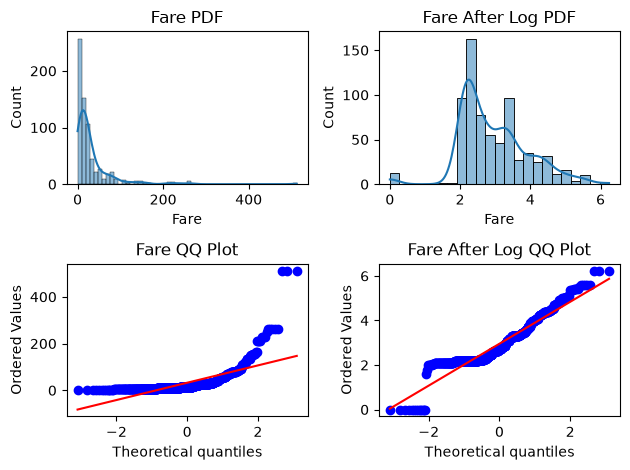

In [71]:
# Before log histogram + KDE
plt.subplot(2,2,1)
sns.histplot(X_train['Fare'], kde=True)
plt.title('Fare PDF')

# After log histogram + KDE
plt.subplot(2,2,2)
sns.histplot(X_train_transformed['Fare'], kde=True)
plt.title('Fare After Log PDF')

# Before log QQ plot
plt.subplot(2,2,3)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title('Fare QQ Plot')

# After log QQ plot
plt.subplot(2,2,4)
stats.probplot(X_train_transformed['Fare'], dist="norm", plot=plt)
plt.title('Fare After Log QQ Plot')

plt.tight_layout()
plt.show()

#### Other Transformation

In [72]:
#Function for custom transform

def apply_transform(transform):
    X = df.iloc[:,1:3]
    y = df.iloc[:,0]
    
    trf = ColumnTransformer([('fare_transform',FunctionTransformer(transform),['Fare'])],remainder='passthrough')
    
    X_trans = trf.fit_transform(X)
    
    clf = LogisticRegression()
    
    print("Accuracy",np.mean(cross_val_score(clf,X_trans,y,scoring='accuracy',cv=10)))
    
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')

    plt.subplot(122)
    stats.probplot(X_trans[:,0], dist="norm", plot=plt)
    plt.title('Fare After Transform')

    plt.show()

Accuracy 0.6431335830212235


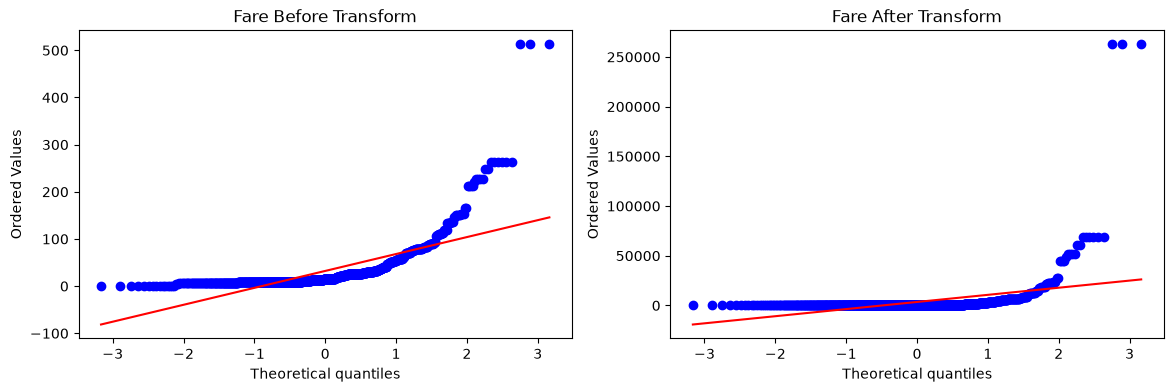

In [73]:
#Square Transform
apply_transform(lambda x: x**2)

Accuracy 0.6589013732833957


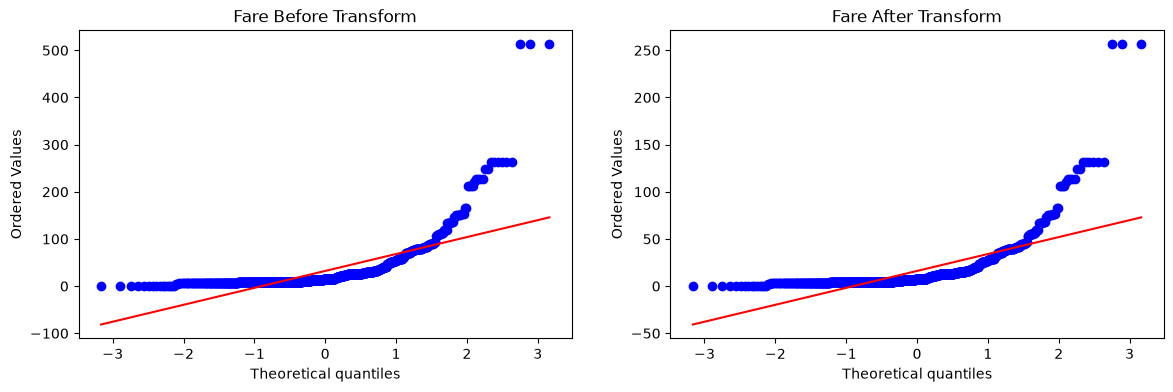

In [74]:
#Square Root Transform
apply_transform(lambda x: x**1/2)

Accuracy 0.61729088639201


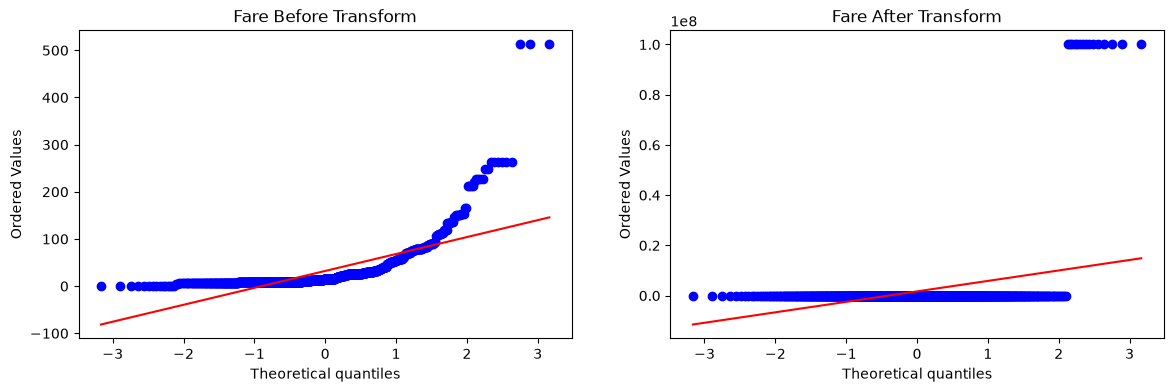

In [75]:
#Reciprocal Transform
apply_transform(lambda x: 1/(x+0.00000001))

Accuracy 0.6195131086142323


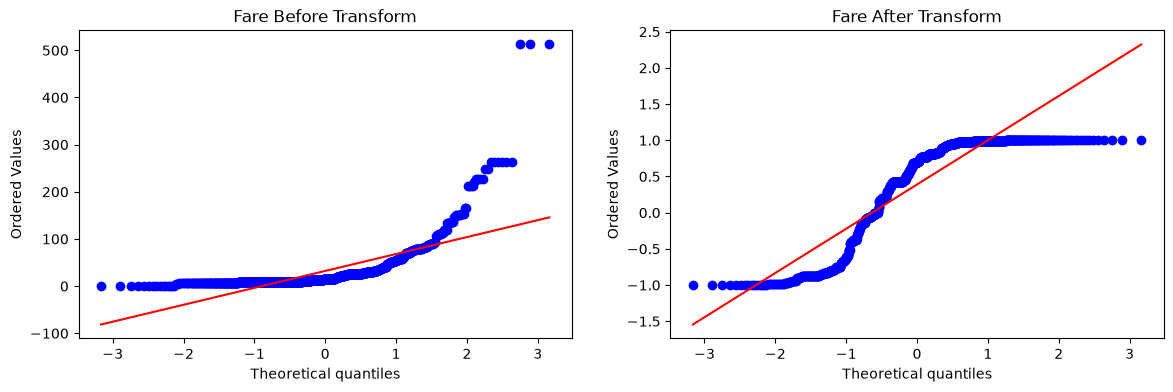

In [76]:
#Square Root Transform
apply_transform(np.sin)

### Power Transform

In [77]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from sklearn.preprocessing import PowerTransformer

In [78]:
df = pd.read_csv('DataSets/concrete_data.csv')
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [79]:
df.shape

(1030, 9)

In [80]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [81]:
df.describe()    #Checking if any negative or zero value and min is 0 but no negative values

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [82]:
X = df.drop(columns=['Strength'])
y = df.iloc[:,-1]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# Applying Regression without any transformation
lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
print("R2 Score before Box-Cox Transform",r2_score(y_test,y_pred))


# Cross checking with cross val score
lr = LinearRegression()
print("R2 cross validated score before Box-Cox Transform",np.mean(cross_val_score(lr,X,y,scoring='r2')))


# Applying Box-Cox Transform
pt = PowerTransformer(method='box-cox')
X_train_transformed = pt.fit_transform(X_train+0.000001)  #This was done to deal with zero value
X_test_transformed = pt.transform(X_test+0.000001)
print("All lambda values of all columns")
print(pd.DataFrame({'cols':X_train.columns,'box_cox_lambdas':pt.lambdas_}))
# We have a dictionary where keys are cols and box_cox_lambdas
# X_train.columns are values which are actually a list -> ['Age','Fare']
# pt.lambas_ where pt = PowerTransformer(method='box-cox') and 
# .lambas_ access stored learned values which were calculated by pt.fit(X_train) and stored them internally inside pt

# Applying linear regression on transformed data
lr = LinearRegression()
lr.fit(X_train_transformed,y_train)
y_pred2 = lr.predict(X_test_transformed)
print("R2 Score after Box-Cox Transform",r2_score(y_test,y_pred2))


# Using cross val score
pt = PowerTransformer(method='box-cox')
X_transformed = pt.fit_transform(X+0.0000001)
lr = LinearRegression()
print("R2 cross validated score after Box-Cox Transform",np.mean(cross_val_score(lr,X_transformed,y,scoring='r2')))

R2 Score before Box-Cox Transform 0.6275531792314848
R2 cross validated score before Box-Cox Transform 0.4609940491662864


All lambda values of all columns
                 cols  box_cox_lambdas
0              Cement         0.177025
1  Blast Furnace Slag         0.025093
2             Fly Ash        -0.038970
3               Water         0.772682
4    Superplasticizer         0.098811
5    Coarse Aggregate         1.129813
6      Fine Aggregate         1.782018
7                 Age         0.066631
R2 Score after Box-Cox Transform 0.8047825008078886
R2 cross validated score after Box-Cox Transform 0.6658537941434357


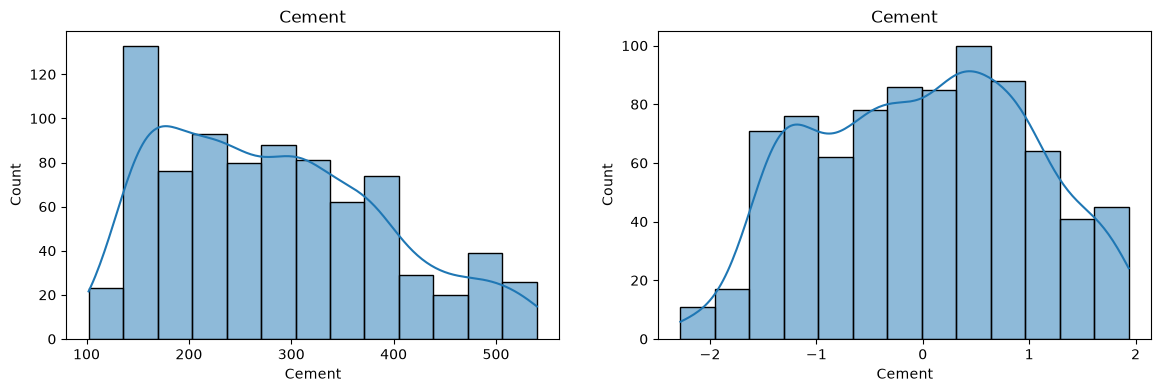

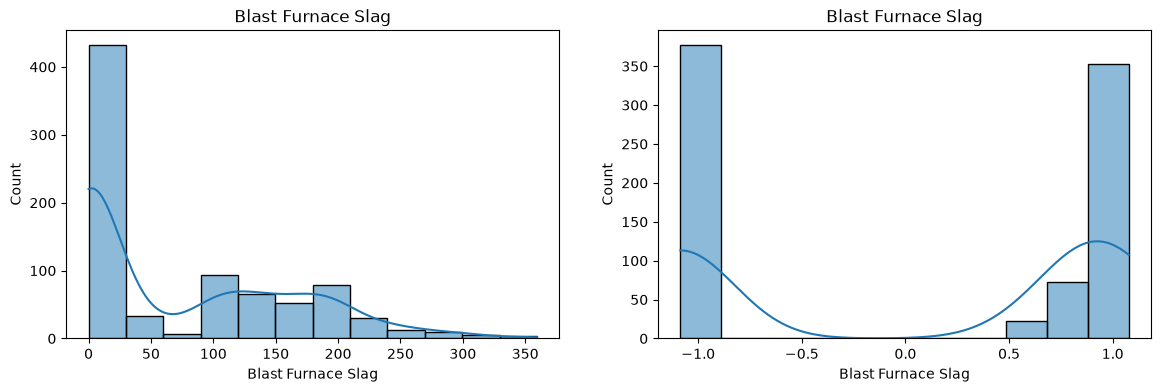

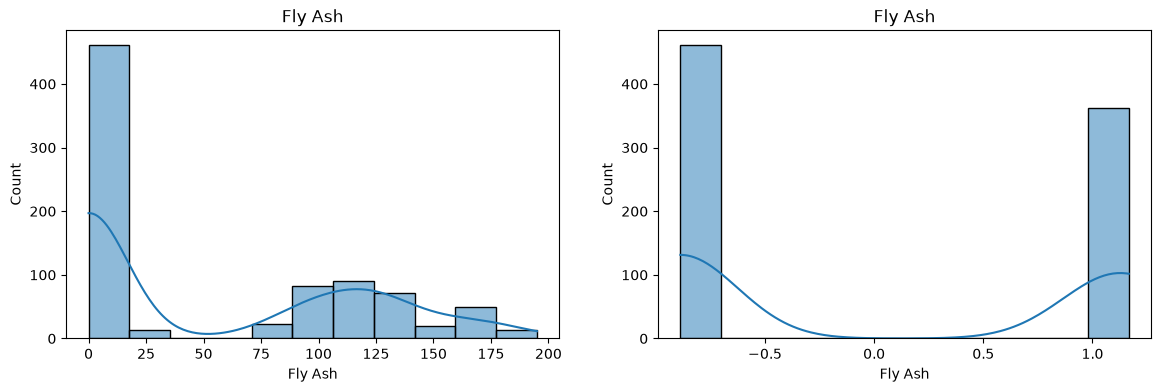

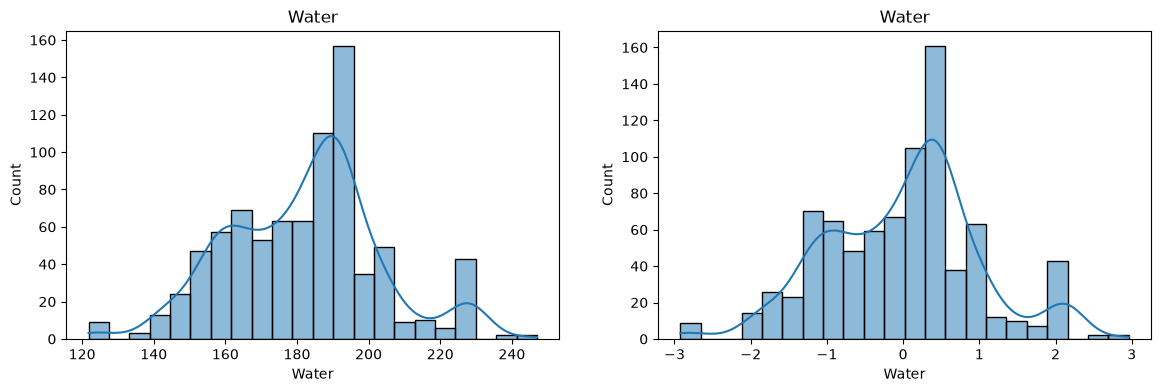

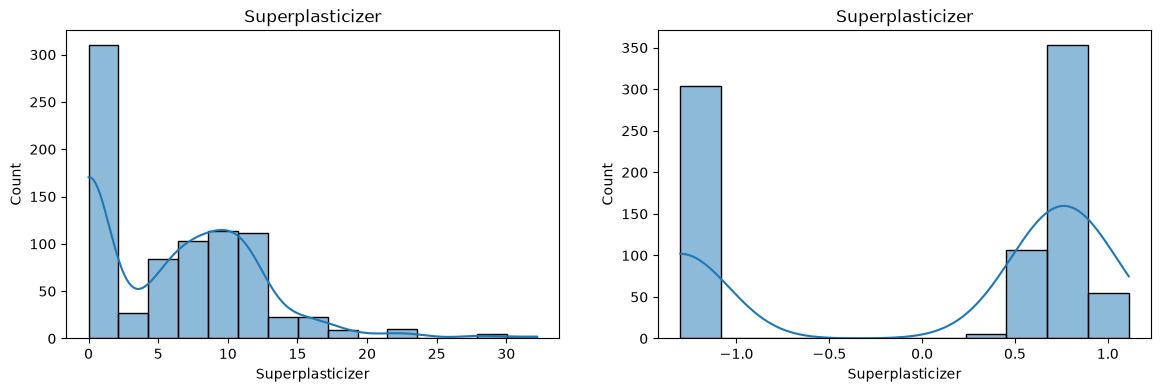

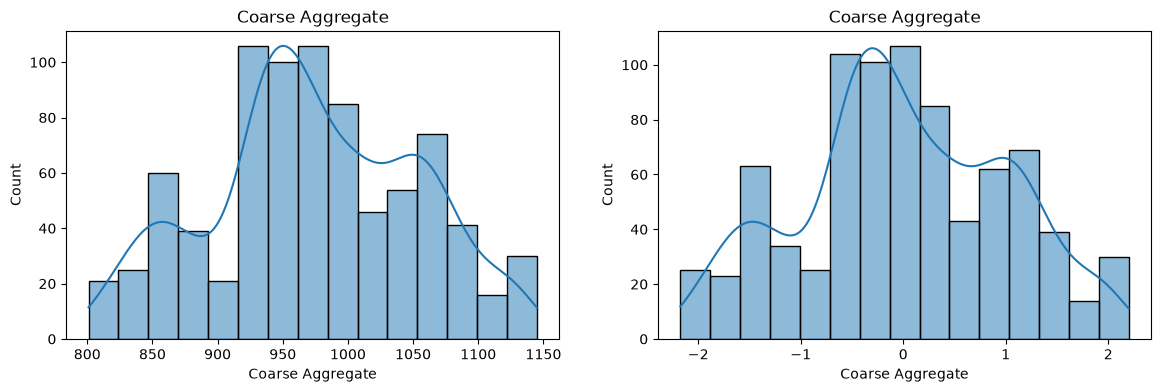

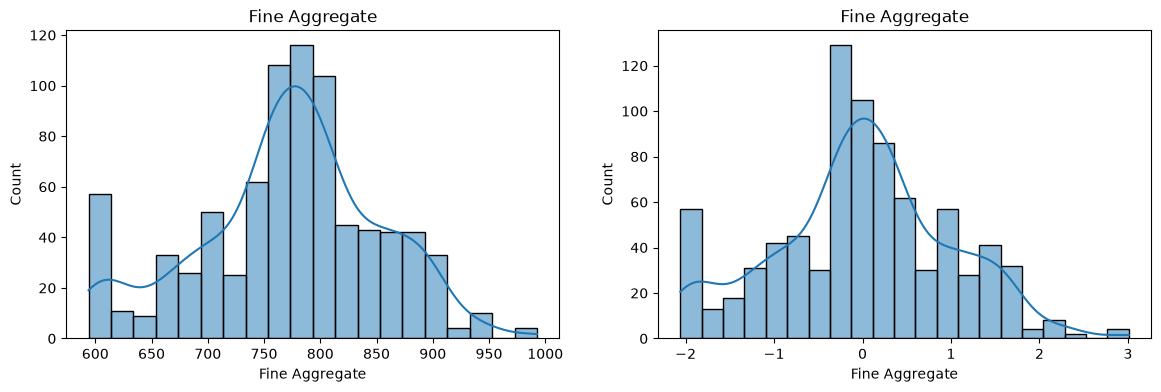

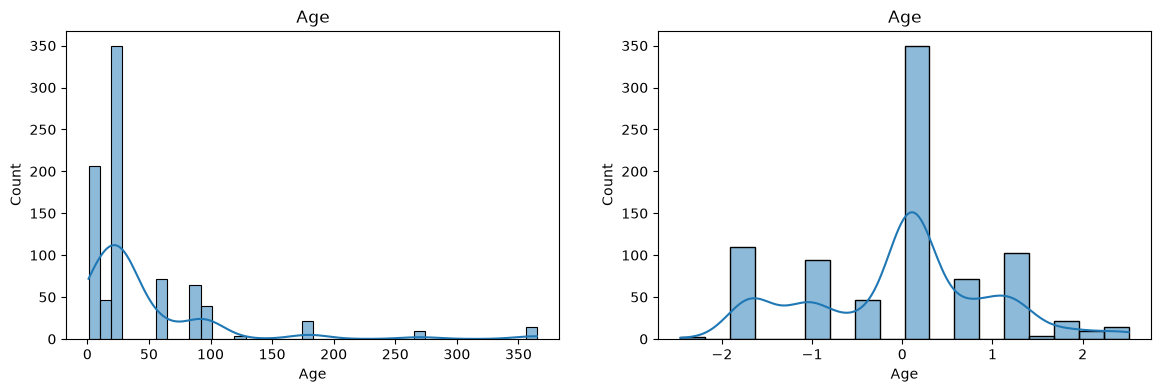

In [83]:
# Before and after comparision for Box-Cox Plot
X_train_transformed = pd.DataFrame(X_train_transformed,columns=X_train.columns)

for col in X_train_transformed.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col],kde = True)
    plt.title(col)

    plt.subplot(122)
    sns.histplot(X_train_transformed[col],kde = True)
    plt.title(col)

    plt.show()

In [84]:
# Apply Yeo-Johnson transform
pt1 = PowerTransformer()
X_train_transformed2 = pt1.fit_transform(X_train)
X_test_transformed2 = pt1.transform(X_test)
lr = LinearRegression()
lr.fit(X_train_transformed2,y_train)
y_pred3 = lr.predict(X_test_transformed2)
print("R2 Score after Yeo-Johnson transform ", r2_score(y_test,y_pred3))

print("All lambda values of all columns")
print(pd.DataFrame({'cols':X_train.columns,'Yeo_Johnson_lambdas':pt1.lambdas_}))


# applying cross val score
pt = PowerTransformer()
X_transformed2 = pt.fit_transform(X)
lr = LinearRegression()
print("R2 cross validated score after Yeo-Johnson Transform" ,np.mean(cross_val_score(lr,X_transformed2,y,scoring='r2')))

R2 Score after Yeo-Johnson transform  0.8161906510869553
All lambda values of all columns
                 cols  Yeo_Johnson_lambdas
0              Cement             0.174348
1  Blast Furnace Slag             0.015715
2             Fly Ash            -0.161447
3               Water             0.771307
4    Superplasticizer             0.253935
5    Coarse Aggregate             1.130050
6      Fine Aggregate             1.783100
7                 Age             0.019885
R2 cross validated score after Yeo-Johnson Transform 0.683462515116388


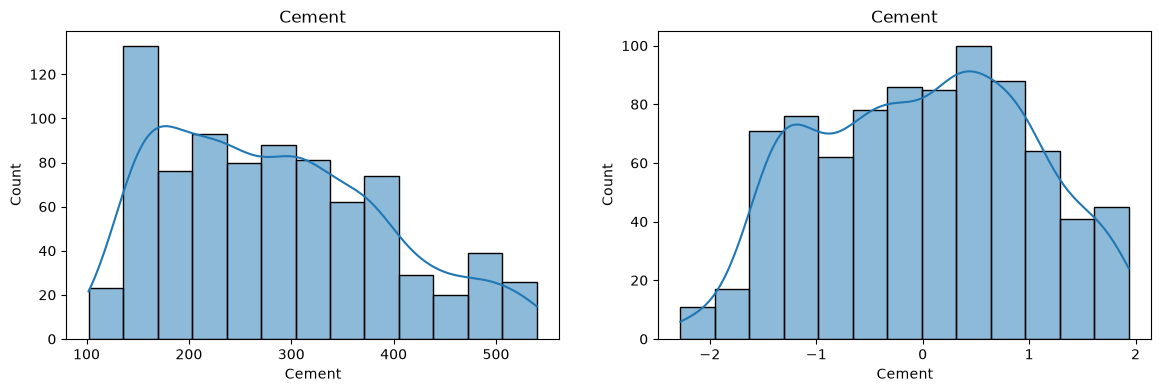

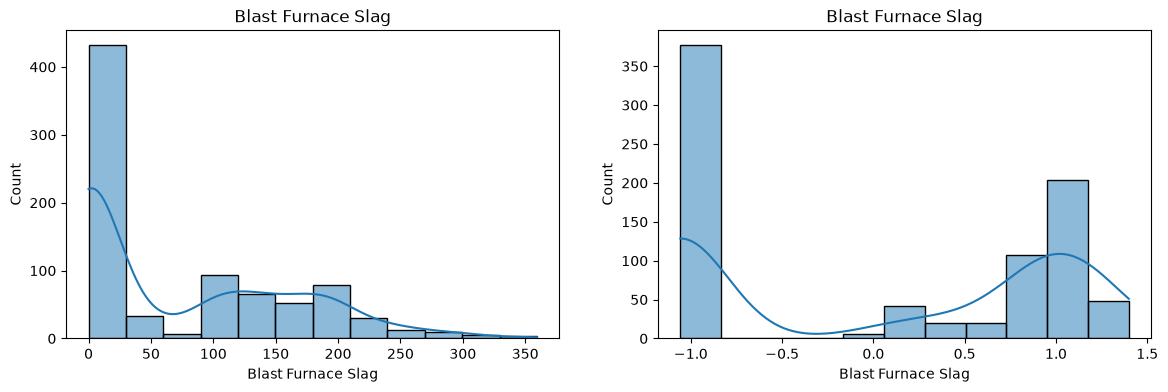

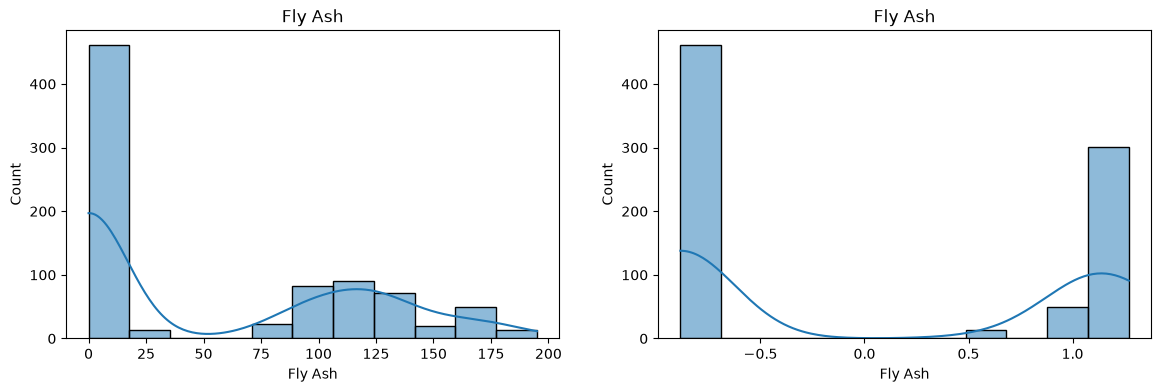

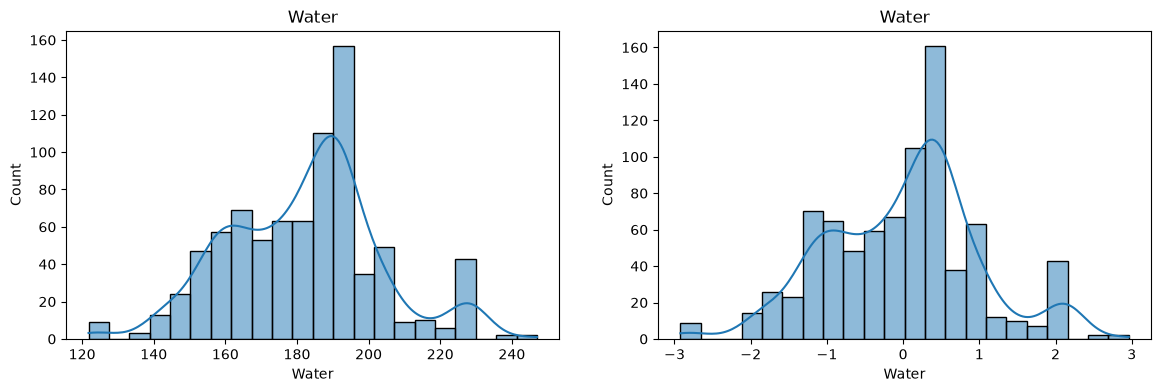

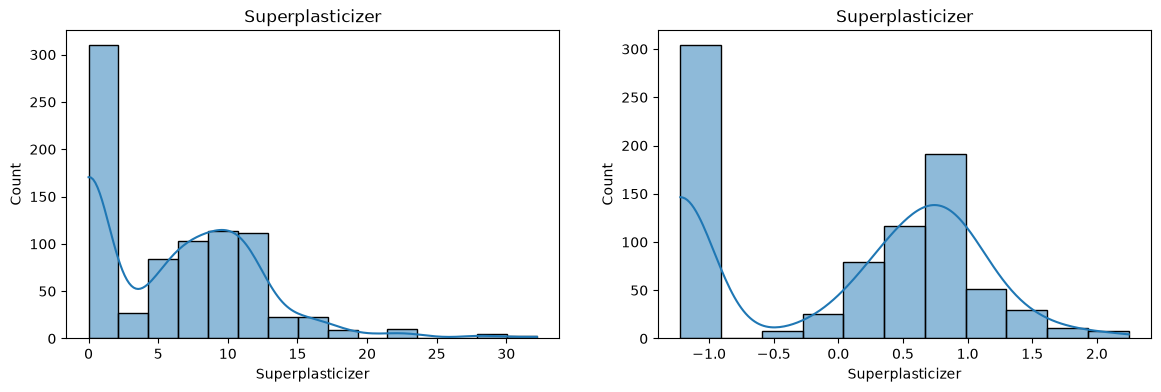

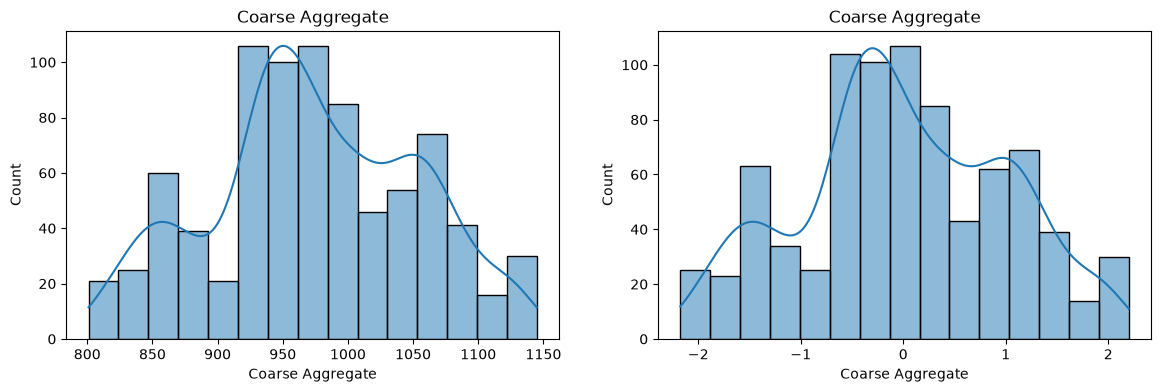

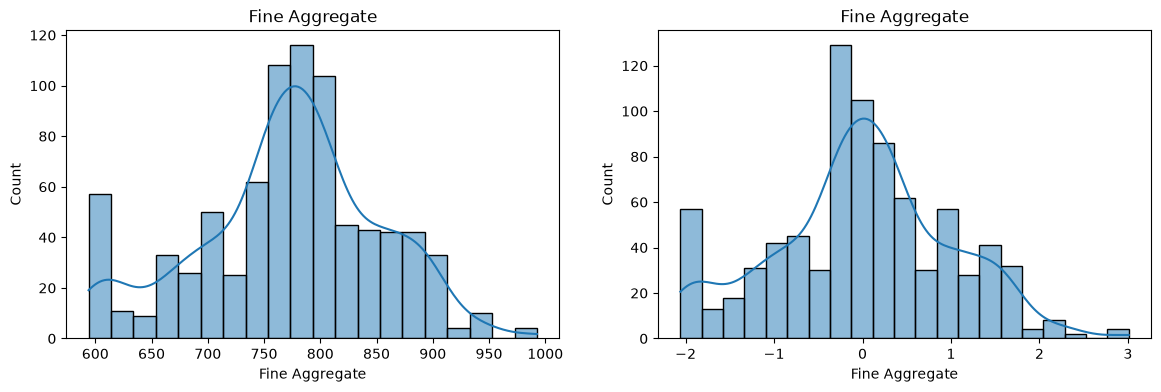

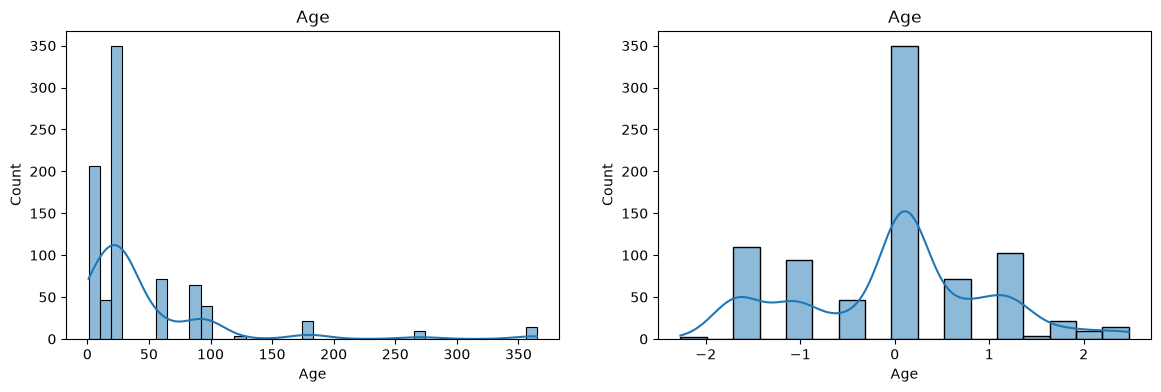

In [85]:
# Before and after comparision for Yeo-Johnson Plot
X_train_transformed2 = pd.DataFrame(X_train_transformed2,columns=X_train.columns)

for col in X_train_transformed2.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col],kde = True)
    plt.title(col)

    plt.subplot(122)
    sns.histplot(X_train_transformed2[col],kde = True)
    plt.title(col)

    plt.show()

In [86]:
#FULL ACCURACY COMPARISON
print("R2 Score before Box-Cox Transform",r2_score(y_test,y_pred))
print("R2 cross validated score before Box-Cox Transform",np.mean(cross_val_score(lr,X,y,scoring='r2')))
print("R2 Score after Box-Cox Transform",r2_score(y_test,y_pred2))
print("R2 cross validated score after Box-Cox Transform",np.mean(cross_val_score(lr,X_transformed,y,scoring='r2')))
print("R2 Score after Yeo-Johnson transform ", r2_score(y_test,y_pred3))
print("R2 cross validated score after Yeo-Johnson Transform" ,np.mean(cross_val_score(lr,X_transformed2,y,scoring='r2')))

R2 Score before Box-Cox Transform 0.6275531792314848
R2 cross validated score before Box-Cox Transform 0.4609940491662864
R2 Score after Box-Cox Transform 0.8047825008078886
R2 cross validated score after Box-Cox Transform 0.6658537941434357
R2 Score after Yeo-Johnson transform  0.8161906510869553
R2 cross validated score after Yeo-Johnson Transform 0.683462515116388


## Encoding Numerical Data

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

### Discretization/Binning

In [88]:
df = pd.read_csv('DataSets/titanic.csv',usecols=['Age','Fare','Survived'])
df.dropna(inplace=True)
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [89]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

kbin_age = KBinsDiscretizer(n_bins=15,encode='ordinal',strategy='quantile',quantile_method='averaged_inverted_cdf')
kbin_fare = KBinsDiscretizer(n_bins=15,encode='ordinal',strategy='quantile',quantile_method='averaged_inverted_cdf')

trf = ColumnTransformer([
    ('first',kbin_age,[0]),
    ('second',kbin_fare,[1])
])

X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [90]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42,  6.  , 16.  , 19.  , 21.  , 23.  , 25.  , 28.  , 30.  ,
              32.  , 35.  , 38.  , 42.  , 47.  , 54.  , 80.  ])             ],
      dtype=object)

In [91]:
output = pd.DataFrame({
    'age':X_train['Age'],
    'age_trf':X_train_trf[:,0],
    'fare':X_train['Fare'],
    'fare_trf':X_train_trf[:,1]
})
output.sample(5)

,age,age_trf,fare,fare_trf
401,26.0,6.0,8.050,3.0
714,52.0,13.0,13.000,6.0
331,45.5,12.0,28.500,10.0
203,45.5,12.0,7.225,0.0
81,29.0,7.0,9.500,4.0


In [92]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)
y_pred2 = clf.predict(X_test_trf)
accuracy_score(y_test,y_pred2)

0.6363636363636364

In [93]:
#This is same thing we did above but just with a function to run and plot
def discretize(bins,strategy):
    kbin_age = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    
    trf = ColumnTransformer([
        ('first',kbin_age,[0]),
        ('second',kbin_fare,[1])
    ])
    
    X_trf = trf.fit_transform(X)
    print(np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy')))
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(X['Age'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(X_trf[:,0],color='red')
    plt.title("After")

    plt.show()
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(X['Fare'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(X_trf[:,1],color='red')
    plt.title("Fare")

    plt.show()

0.6317097026604068


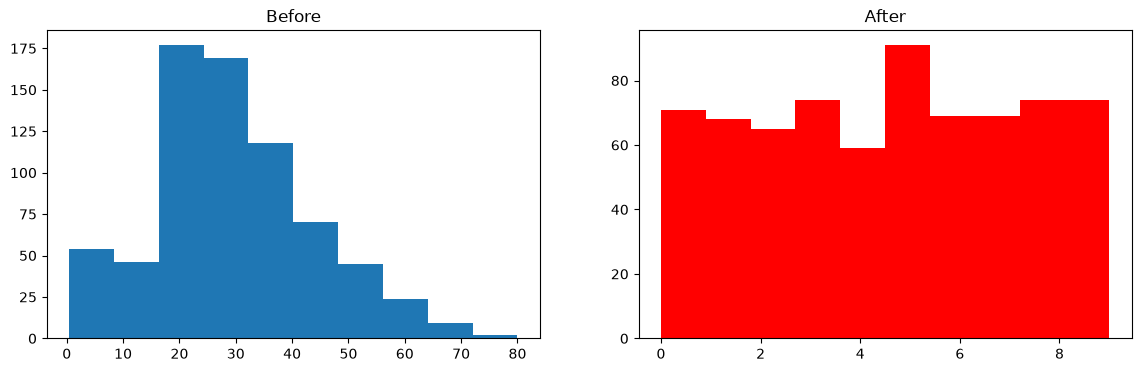

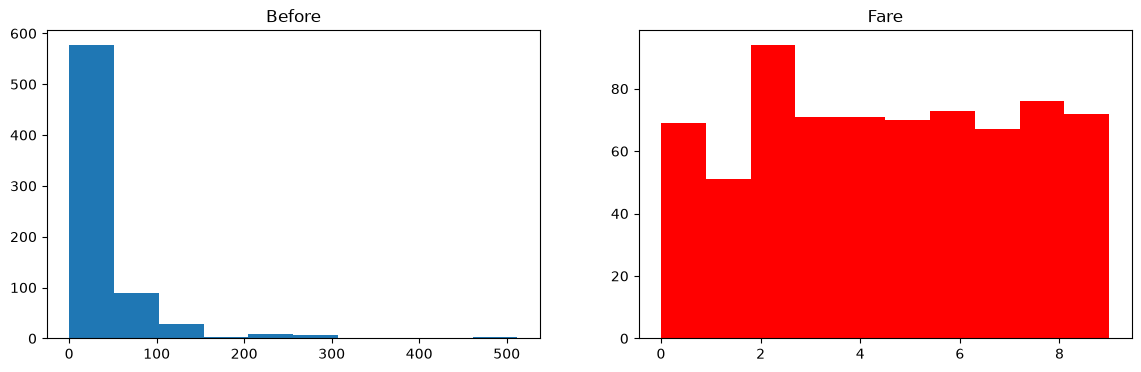

In [94]:
discretize(10,'quantile')

0.630281690140845


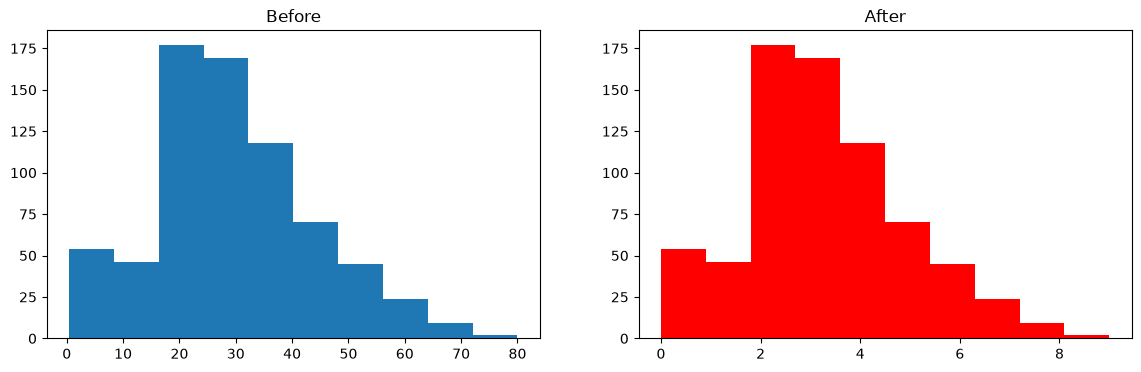

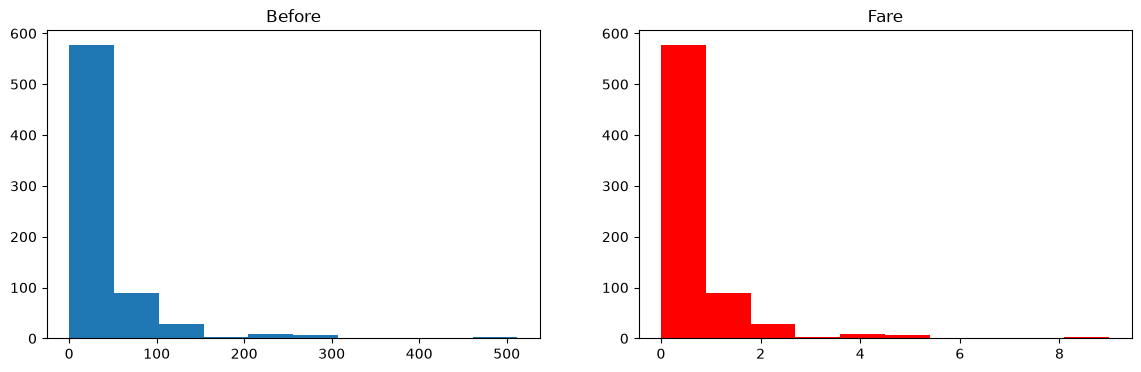

In [95]:
discretize(10,'uniform')

0.6358959311424099


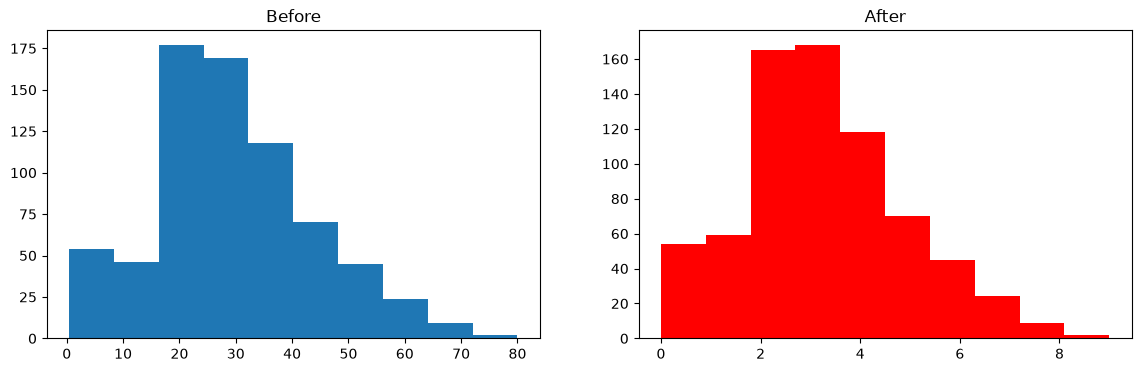

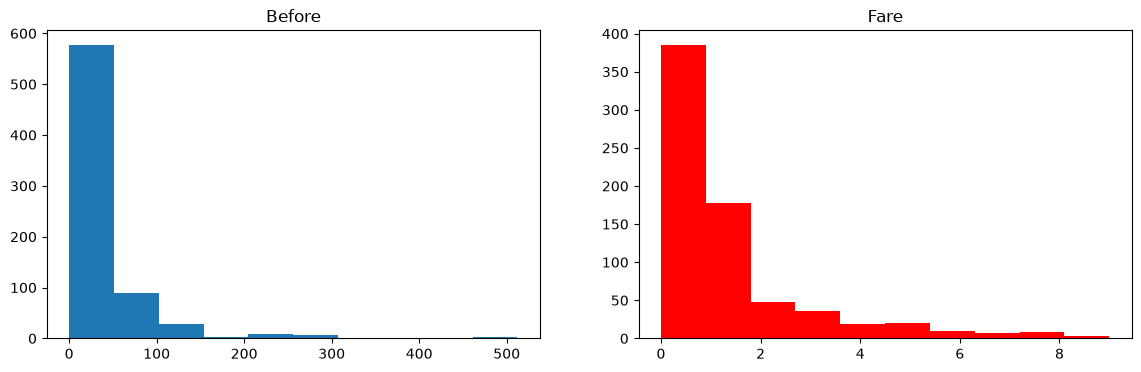

In [96]:
discretize(10,'kmeans')

### Binarization

In [97]:
from sklearn.preprocessing import Binarizer

In [98]:
df = pd.read_csv('DataSets/titanic.csv')[['Age','Fare','SibSp','Parch','Survived']]
df.dropna(inplace=True)

df['family'] = df['SibSp'] + df['Parch']
df.drop(columns=['SibSp','Parch'],inplace=True)

In [99]:
X = df.drop(columns=['Survived'])
y = df['Survived']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

trf = ColumnTransformer([('bin',Binarizer(copy=False),['family'])
],remainder='passthrough')

X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

print(pd.DataFrame(X_train_trf,columns=['family','Age','Fare']))

clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)
y_pred2 = clf.predict(X_test_trf)

accuracy_score(y_test,y_pred2)

     family   Age      Fare
0       1.0  31.0   20.5250
1       1.0  26.0   14.4542
2       1.0  30.0   16.1000
3       0.0  33.0    7.7750
4       0.0  25.0   13.0000
..      ...   ...       ...
566     1.0  46.0   61.1750
567     0.0  25.0   13.0000
568     0.0  41.0  134.5000
569     1.0  33.0   20.5250
570     0.0  33.0    7.8958

[571 rows x 3 columns]


0.6083916083916084

In [100]:
trf = ColumnTransformer([
    ('bin',Binarizer(copy=False),['family'])
],remainder='passthrough')